<a href="https://colab.research.google.com/github/YanuarRamadhaniKuswoko/PCVK_Sem5/blob/main/Pertemuan5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##E-1 PERCOBAAN HISTOGRAM

 Import folder yang ada di Drive Anda dengan cara sebagai berikut

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Import beberapa library berikut yang akan digunakan selama uji coba praktikum
minggu ke-5 berikut.

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

 Membuat histogram citra berdasarkan flowchart di bawah ini. Tahap 1 gunakan citra
contoh lena.jpg dan cocokkan keluarannya dengan gambar contoh pada modul;
setelah cocok, tahap 2 ulangi dengan citra KTM1b.jpg milik Anda sendiri.


Lena

<BarContainer object of 256 artists>

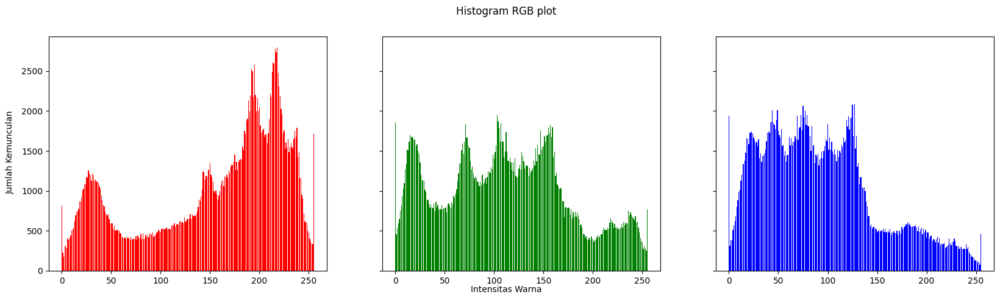

In [ ]:
# membuat histogram image (manual)
img = cv.imread(
    "/content/drive/MyDrive/PCVK/lena.jpg"
)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(0, height):
  for x in range(0, width):
    red[img[y][x][0]] += 1
    green[img[y][x][1]] += 1
    blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20, 5], sharex=True, sharey=True)
fig.suptitle("Histogram RGB plot")
fig.text(0.09, 0.5, "Jumlah Kemunculan", va="center", rotation="vertical")
fig.text(0.5, 0.04, "Intensitas Warna", ha="center")
axs[0].bar(names, red, color="red")
axs[1].bar(names, green, color="green")
axs[2].bar(names, blue, color="blue")

KTM1b

<BarContainer object of 256 artists>

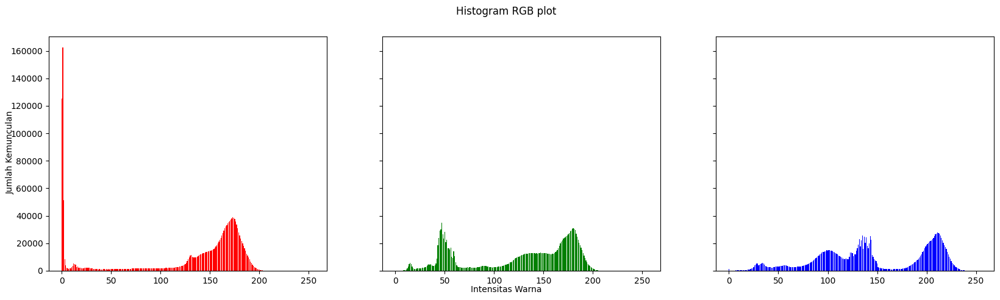

In [ ]:
# membuat histogram image (manual)
img = cv.imread(
    "/content/drive/MyDrive/PCVK/KTM1b.jpg"
)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(0, height):
  for x in range(0, width):
    red[img[y][x][0]] += 1
    green[img[y][x][1]] += 1
    blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20, 5], sharex=True, sharey=True)
fig.suptitle("Histogram RGB plot")
fig.text(0.09, 0.5, "Jumlah Kemunculan", va="center", rotation="vertical")
fig.text(0.5, 0.04, "Intensitas Warna", ha="center")
axs[0].bar(names, red, color="red")
axs[1].bar(names, green, color="green")
axs[2].bar(names, blue, color="blue")

*PERTANYAAN PRAKTIKUM E1*
1. Buatlah histogram citra yang sama menggunakan library NumPy, yaitu
numpy.histogram, dan juga cv.calcHist. Bandingkan ketiganya dengan menghitung
selisih maksimum antar hasil. Selisihnya harus nol; tampilkan pembuktiannya pada
lena.jpg lebih dulu, kemudian ulangi pada KTM1b.jpg.

jawab:



In [ ]:
import cv2 as cv
import numpy as np

def hitung_dan_bandingkan_histogram(file_path):
    img = cv.imread(file_path)
    if img is None:
        print(f"File {file_path} tidak ditemukan.")
        return

    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    height, width, _ = img_rgb.shape

    # 1. Metode Manual
    red_manual = np.zeros(256, dtype=int)
    green_manual = np.zeros(256, dtype=int)
    blue_manual = np.zeros(256, dtype=int)

    for y in range(height):
        for x in range(width):
            red_manual[img_rgb[y, x, 0]] += 1
            green_manual[img_rgb[y, x, 1]] += 1
            blue_manual[img_rgb[y, x, 2]] += 1

    # 2. Metode NumPy (np.histogram)
    red_np, _ = np.histogram(img_rgb[:, :, 0], bins=256, range=(0, 256))
    green_np, _ = np.histogram(img_rgb[:, :, 1], bins=256, range=(0, 256))
    blue_np, _ = np.histogram(img_rgb[:, :, 2], bins=256, range=(0, 256))

    # 3. Metode OpenCV (cv.calcHist)
    red_cv = cv.calcHist([img_rgb], [0], None, [256], [0, 256]).ravel().astype(int)
    green_cv = cv.calcHist([img_rgb], [1], None, [256], [0, 256]).ravel().astype(int)
    blue_cv = cv.calcHist([img_rgb], [2], None, [256], [0, 256]).ravel().astype(int)

    # Hitung Selisih Maksimum
    diff_manual_np = [
        np.max(np.abs(red_manual - red_np)),
        np.max(np.abs(green_manual - green_np)),
        np.max(np.abs(blue_manual - blue_np))
    ]

    diff_manual_cv = [
        np.max(np.abs(red_manual - red_cv)),
        np.max(np.abs(green_manual - green_cv)),
        np.max(np.abs(blue_manual - blue_cv))
    ]

    diff_np_cv = [
        np.max(np.abs(red_np - red_cv)),
        np.max(np.abs(green_np - green_cv)),
        np.max(np.abs(blue_np - blue_cv))
    ]

    print(f"=== Pembuktian Selisih Histogram: {file_path} ===")
    print(f"Selisih Maksimum (Manual vs NumPy)  : R={diff_manual_np[0]}, G={diff_manual_np[1]}, B={diff_manual_np[2]}")
    print(f"Selisih Maksimum (Manual vs OpenCV) : R={diff_manual_cv[0]}, G={diff_manual_cv[1]}, B={diff_manual_cv[2]}")
    print(f"Selisih Maksimum (NumPy vs OpenCV)  : R={diff_np_cv[0]}, G={diff_np_cv[1]}, B={diff_np_cv[2]}\n")

# Eksekusi Pembuktian
hitung_dan_bandingkan_histogram("/content/drive/MyDrive/PCVK/lena.jpg")
hitung_dan_bandingkan_histogram("/content/drive/MyDrive/PCVK/KTM1b.jpg")

=== Pembuktian Selisih Histogram: /content/drive/MyDrive/PCVK/lena.jpg ===
Selisih Maksimum (Manual vs NumPy)  : R=0, G=0, B=0
Selisih Maksimum (Manual vs OpenCV) : R=0, G=0, B=0
Selisih Maksimum (NumPy vs OpenCV)  : R=0, G=0, B=0

=== Pembuktian Selisih Histogram: /content/drive/MyDrive/PCVK/KTM1b.jpg ===
Selisih Maksimum (Manual vs NumPy)  : R=0, G=0, B=0
Selisih Maksimum (Manual vs OpenCV) : R=0, G=0, B=0
Selisih Maksimum (NumPy vs OpenCV)  : R=0, G=0, B=0



2. Gambarkan histogram ternormalisasi p(j) dan kurva CDF untuk KTM1a.jpg sampai
KTM1d.jpg dalam satu figure 2 x 2. Jelaskan perbedaan bentuk kurva CDF antara citra
paling gelap dan citra paling terang milik Anda, lalu kaitkan dengan kondisi
pencahayaan saat akuisisi pada Pertemuan 2.

jawab:

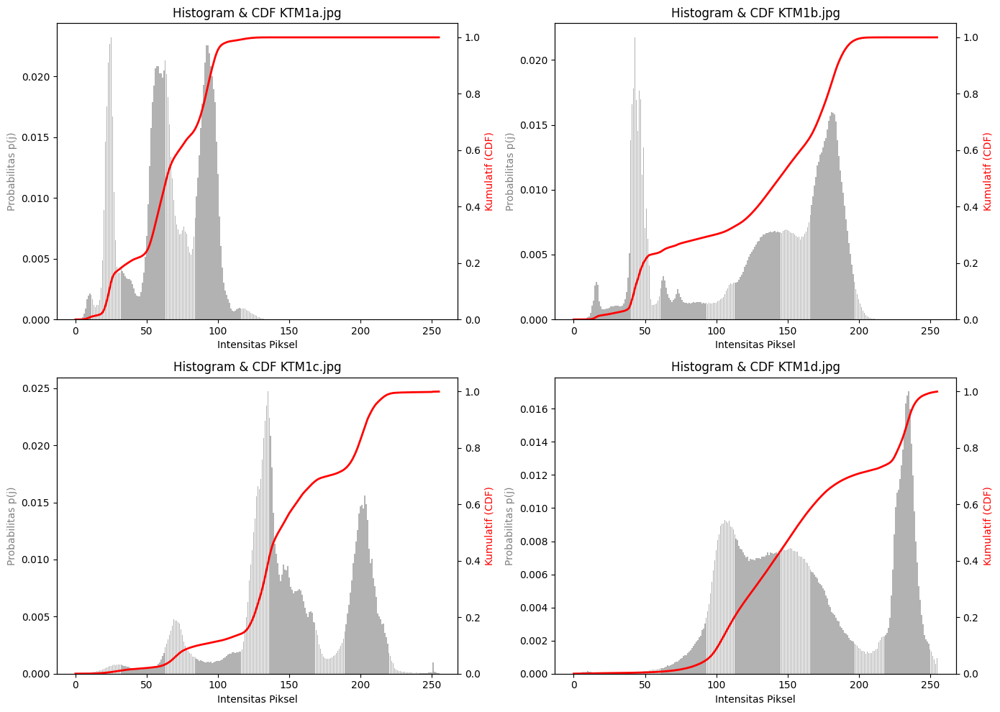

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

files = [
    "/content/drive/MyDrive/PCVK/KTM1a.jpg",
    "/content/drive/MyDrive/PCVK/KTM1b.jpg",
    "/content/drive/MyDrive/PCVK/KTM1c.jpg",
    "/content/drive/MyDrive/PCVK/KTM1d.jpg"
]

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()

for idx, file_path in enumerate(files):
    img = cv.imread(file_path, cv.IMREAD_GRAYSCALE)
    if img is None:
        continue

    # Hitung Histogram & Normalisasi p(j)
    hist = cv.calcHist([img], [0], None, [256], [0, 256]).ravel()
    p_j = hist / hist.sum()

    # Hitung CDF
    cdf = p_j.cumsum()

    # Plot p(j)
    ax1 = axs[idx]
    ax1.bar(range(256), p_j, color='gray', alpha=0.6, label='p(j)')
    ax1.set_xlabel('Intensitas Piksel')
    ax1.set_ylabel('Probabilitas p(j)', color='gray')
    ax1.set_title(f"Histogram & CDF KTM1{chr(97+idx)}.jpg")

    # Plot CDF (Sumbu Y Sekunder)
    ax2 = ax1.twinx()
    ax2.plot(range(256), cdf, color='red', linewidth=2, label='CDF')
    ax2.set_ylabel('Kumulatif (CDF)', color='red')
    ax2.set_ylim([0, 1.05])

plt.tight_layout()
plt.show()

3. Ulangi histogram KTM1b.jpg dengan jumlah bin sebesar PARAM['bins'] dan dengan
256 bin. Tampilkan keduanya berdampingan dan jelaskan informasi apa yang hilang
ketika jumlah bin dikurangi.

jawab:

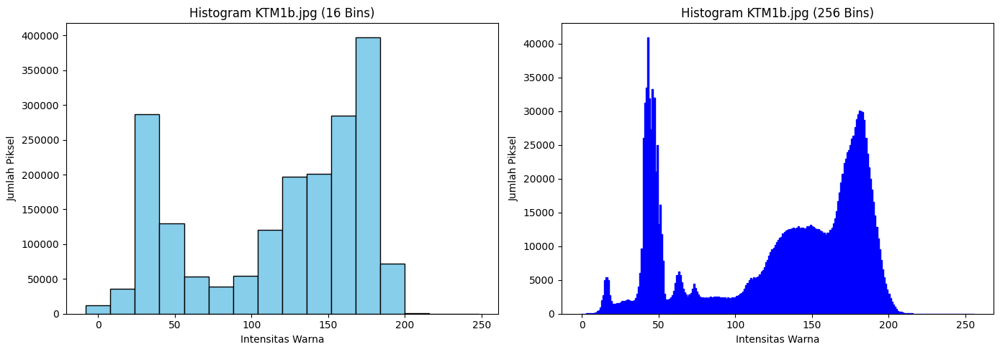

In [ ]:
PARAM = {'bins': 16}  # Sesuaikan nilai bin sesuai parameter praktikum Anda

img = cv.imread("/content/drive/MyDrive/PCVK/KTM1b.jpg", cv.IMREAD_GRAYSCALE)

# Hitung Histogram
hist_reduced, bin_edges_reduced = np.histogram(img, bins=PARAM['bins'], range=(0, 256))
hist_full, bin_edges_full = np.histogram(img, bins=256, range=(0, 256))

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Plot Bins Berkurang
axs[0].bar(bin_edges_reduced[:-1], hist_reduced, width=256/PARAM['bins'], edgecolor='black', color='skyblue')
axs[0].set_title(f"Histogram KTM1b.jpg ({PARAM['bins']} Bins)")
axs[0].set_xlabel("Intensitas Warna")
axs[0].set_ylabel("Jumlah Piksel")

# Plot 256 Bins
axs[1].bar(bin_edges_full[:-1], hist_full, width=1, edgecolor='blue', color='blue')
axs[1].set_title("Histogram KTM1b.jpg (256 Bins)")
axs[1].set_xlabel("Intensitas Warna")
axs[1].set_ylabel("Jumlah Piksel")

plt.tight_layout()
plt.show()

## E-2 PERCOBAAN HISTOGRAM EQUALIZATION

1. Buatlah histogram equalization beserta tampilan citra sebelum dan sesudah proses,
berdasarkan flowchart di bawah ini. Tahap 1 gunakan citra contoh lena_lc.jpg dan
cocokkan hasilnya dengan gambar contoh pada modul; tahap 2 ulangi pada citra
KTM1a.jpg milik Anda, yaitu hasil akuisisi di ruangan gelap.

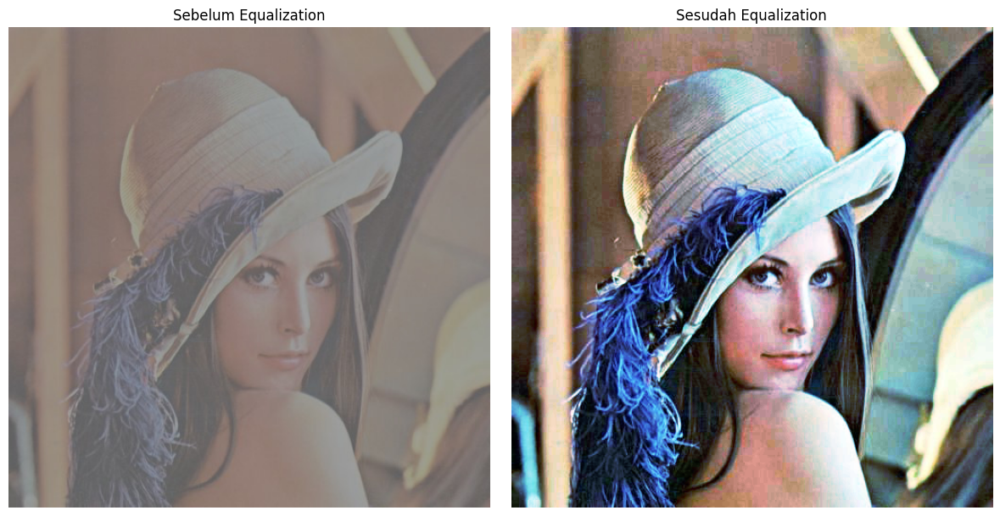

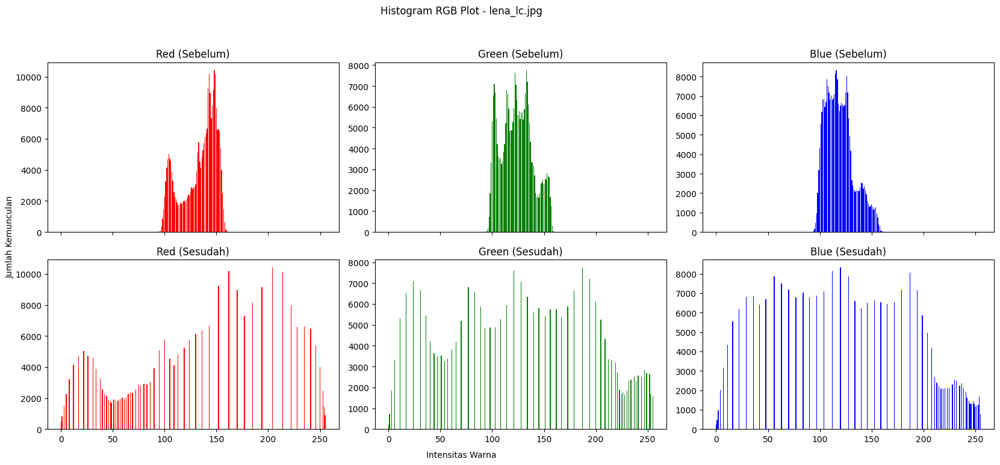

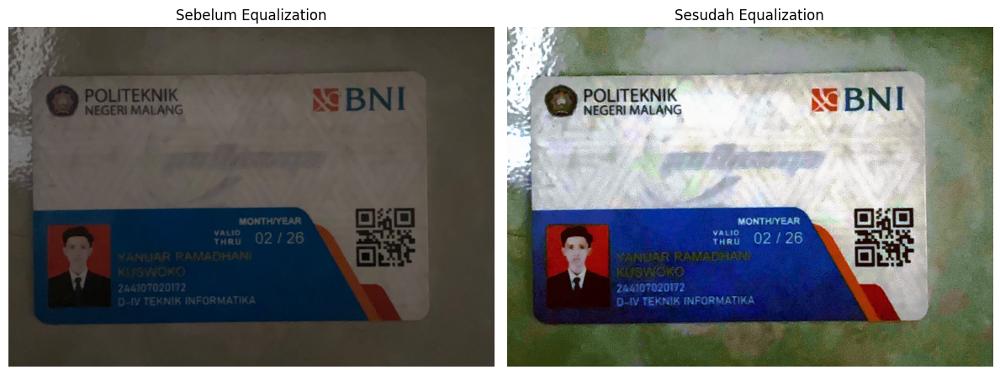

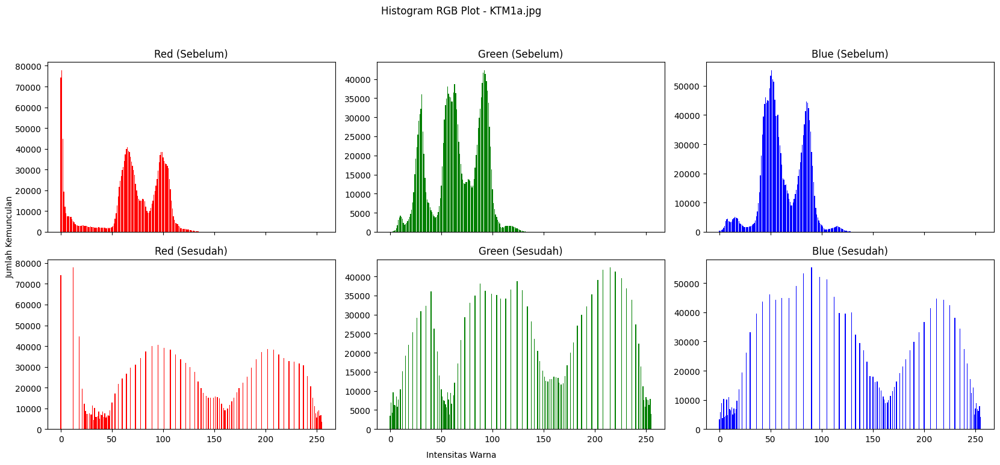

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def proses_histogram_equalization(file_path):
    # 1. Baca Citra
    img_bgr = cv.imread(file_path)
    if img_bgr is None:
        print(f"File {file_path} tidak ditemukan!")
        return

    img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

    # 2. Histogram Equalization Per-Kanal RGB
    img_eq_rgb = np.zeros_like(img_rgb)
    for i in range(3):
        img_eq_rgb[:, :, i] = cv.equalizeHist(img_rgb[:, :, i])

    # 3. Hitung Histogram Manual/OpenCV untuk Plotting
    names = np.arange(256)

    # Histogram Sebelum
    red_before = cv.calcHist([img_rgb], [0], None, [256], [0, 256]).ravel()
    green_before = cv.calcHist([img_rgb], [1], None, [256], [0, 256]).ravel()
    blue_before = cv.calcHist([img_rgb], [2], None, [256], [0, 256]).ravel()

    # Histogram Sesudah
    red_after = cv.calcHist([img_eq_rgb], [0], None, [256], [0, 256]).ravel()
    green_after = cv.calcHist([img_eq_rgb], [1], None, [256], [0, 256]).ravel()
    blue_after = cv.calcHist([img_eq_rgb], [2], None, [256], [0, 256]).ravel()

    # 4. Visualisasi Citra Sebelum & Sesudah
    fig_img, axs_img = plt.subplots(1, 2, figsize=(12, 6))
    axs_img[0].imshow(img_rgb)
    axs_img[0].set_title("Sebelum Equalization")
    axs_img[0].axis("off")

    axs_img[1].imshow(img_eq_rgb)
    axs_img[1].set_title("Sesudah Equalization")
    axs_img[1].axis("off")
    plt.tight_layout()
    plt.show()

    # 5. Visualisasi Plot Histogram (Baris 1: Sebelum, Baris 2: Sesudah)
    fig_hist, axs_hist = plt.subplots(2, 3, figsize=(18, 8), sharex=True)
    fig_hist.suptitle(f"Histogram RGB Plot - {file_path.split('/')[-1]}")

    # Label Sumbu
    fig_hist.text(0.08, 0.5, "Jumlah Kemunculan", va="center", rotation="vertical")
    fig_hist.text(0.5, 0.04, "Intensitas Warna", ha="center")

    # Plot Sebelum
    axs_hist[0, 0].bar(names, red_before, color="red")
    axs_hist[0, 0].set_title("Red (Sebelum)")
    axs_hist[0, 1].bar(names, green_before, color="green")
    axs_hist[0, 1].set_title("Green (Sebelum)")
    axs_hist[0, 2].bar(names, blue_before, color="blue")
    axs_hist[0, 2].set_title("Blue (Sebelum)")

    # Plot Sesudah
    axs_hist[1, 0].bar(names, red_after, color="red")
    axs_hist[1, 0].set_title("Red (Sesudah)")
    axs_hist[1, 1].bar(names, green_after, color="green")
    axs_hist[1, 1].set_title("Green (Sesudah)")
    axs_hist[1, 2].bar(names, blue_after, color="blue")
    axs_hist[1, 2].set_title("Blue (Sesudah)")

    plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])
    plt.show()

# --- Jalankan Tahap 1 & Tahap 2 ---
# Tahap 1: lena_lc.jpg
proses_histogram_equalization("/content/drive/MyDrive/PCVK/lena_lc.jpg")

# Tahap 2: KTM1a.jpg
proses_histogram_equalization("/content/drive/MyDrive/PCVK/KTM1a.jpg")

2. Setelah mengerjakan langkah no. 1, buatlah histogram citra yang sama akan tetapi
menggunakan library yang dimiliki oleh CV2 yaitu “equalizeHist” seperti pada
potongan kode berikut ini.


In [ ]:
import cv2 as cv
import numpy as np

def manual_equalize_hist(channel):
    # Hitung histogram
    hist, _ = np.histogram(channel.flatten(), 256, [0, 256])
    # Hitung Cumulative Distribution Function (CDF)
    cdf = hist.cumsum()
    # Masking nilai 0 agar tidak terbagi saat normalisasi
    cdf_m = np.ma.masked_equal(cdf, 0)
    # Formula Ekualisasi Histogram
    cdf_m = (cdf_m - cdf_m.min()) * 255 / ((channel.shape[0] * channel.shape[1]) - cdf_m.min())
    cdf = np.ma.filled(cdf_m, 0).astype('uint8')
    # Mapping piksel lama ke piksel baru
    return cdf[channel]

def bandingkan_equalization(file_path):
    image = cv.imread(file_path)
    if image is None:
        print(f"File {file_path} tidak ditemukan.")
        return

    b, g, r = cv.split(image)

    # 1. Menggunakan cv2.equalizeHist
    b_cv = cv.equalizeHist(b)
    g_cv = cv.equalizeHist(g)
    r_cv = cv.equalizeHist(r)

    # 2. Menggunakan Implementasi Manual
    b_manual = manual_equalize_hist(b)
    g_manual = manual_equalize_hist(g)
    r_manual = manual_equalize_hist(r)

    # Hitung Selisih Maksimum
    diff_b = np.max(np.abs(b_cv.astype(int) - b_manual.astype(int)))
    diff_g = np.max(np.abs(g_cv.astype(int) - g_manual.astype(int)))
    diff_r = np.max(np.abs(r_cv.astype(int) - r_manual.astype(int)))

    print(f"=== Perbandingan Selisih Maksimum ({file_path.split('/')[-1]}) ===")
    print(f"Selisih Maksimum Kanal B: {diff_b}")
    print(f"Selisih Maksimum Kanal G: {diff_g}")
    print(f"Selisih Maksimum Kanal R: {diff_r}\n")

# Eksekusi Tahap 2
bandingkan_equalization("/content/drive/MyDrive/PCVK/lena_lc.jpg")
bandingkan_equalization("/content/drive/MyDrive/PCVK/KTM1a.jpg")

=== Perbandingan Selisih Maksimum (lena_lc.jpg) ===
Selisih Maksimum Kanal B: 1
Selisih Maksimum Kanal G: 1
Selisih Maksimum Kanal R: 1

=== Perbandingan Selisih Maksimum (KTM1a.jpg) ===
Selisih Maksimum Kanal B: 1
Selisih Maksimum Kanal G: 1
Selisih Maksimum Kanal R: 1



3. Ekualisasi juga dapat diterapkan pada citra berwarna. Cara yang biasanya pertama kali
terpikirkan adalah mengekualisasi kanal biru, hijau, dan merah satu per satu. Jalankan
potongan kode berikut pada citra contoh lena.jpg terlebih dulu, kemudian ulangi pada
KTM1d.jpg milik Anda, dan amati warna yang dihasilkan pada keduanya.

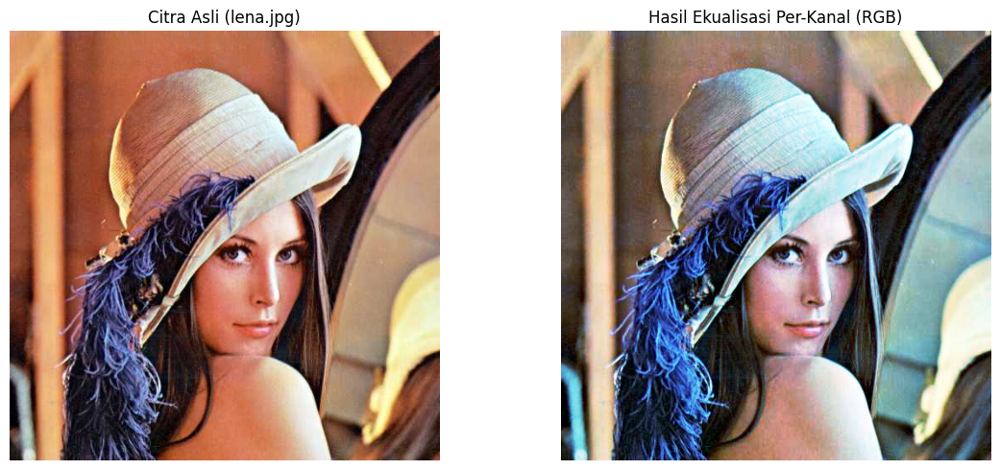

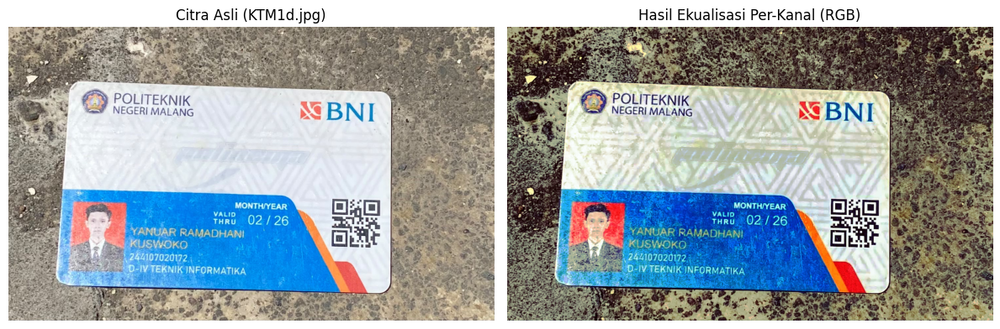

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def ekualisasi_per_kanal(file_path):
    bgr = cv.imread(file_path)
    if bgr is None:
        print(f"File {file_path} tidak ditemukan.")
        return

    # Ekualisasi tiap kanal secara mandiri
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])

    he_bgr = cv.merge(kanal)

    # Konversi ke RGB untuk ditampilkan dengan Matplotlib
    orig_rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
    he_rgb = cv.cvtColor(he_bgr, cv.COLOR_BGR2RGB)

    # Visualisasi Asli vs Hasil Ekualisasi Per Kanal
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    axs[0].imshow(orig_rgb)
    axs[0].set_title(f"Citra Asli ({file_path.split('/')[-1]})")
    axs[0].axis("off")

    axs[1].imshow(he_rgb)
    axs[1].set_title("Hasil Ekualisasi Per-Kanal (RGB)")
    axs[1].axis("off")

    plt.tight_layout()
    plt.show()

# Eksekusi Tahap 3
# 1. Citra lena.jpg
ekualisasi_per_kanal("/content/drive/MyDrive/PCVK/lena.jpg")

# 2. Citra KTM1d.jpg
ekualisasi_per_kanal("/content/drive/MyDrive/PCVK/KTM1d.jpg")

Pengamatan Warna yang Dihasilkan

-Ketika fungsi equalizeHist diterapkan pada masing-masing kanal B, G, dan R secara terpisah, rasio keseimbangan warna menjadi rusak.

-Warna citra terlihat aneh dan terlalu mencolok. Hal ini terjadi karena histogram ekualisasi mengubah luminance sekaligus dan memisahkan nilai relatif warna tiap piksel.

4. Cara kedua memisahkan kecerahan dari informasi warna. Citra diubah ke ruang warna
YCrCb, hanya kanal Y yang diekualisasi, lalu dikembalikan ke BGR. Kanal Cr dan Cb yang
menyimpan informasi warna tidak disentuh sama sekali. Kanal V pada HSV dan kanal
L pada LAB berperan serupa, sehingga ketiganya dicoba sekaligus. (gunakan
KTM1d.jpg)


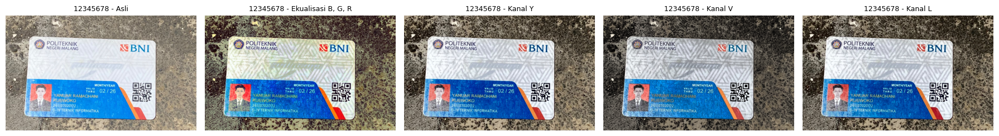

Cara                     Pergeseran Hue Rerata kecerahan
Asli                                  -            162.9
Ekualisasi B, G, R                40.70            126.8
Kanal Y                            1.73            130.4
Kanal V                            2.33            110.2
Kanal L                            3.20            122.3


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Masukkan NIM Anda di sini
NIM = "12345678"  # Contoh: "2141720001"

# Load Citra KTM1d.jpg
berkas = '/content/drive/MyDrive/PCVK/KTM1d.jpg'
bgr = cv.imread(berkas)

if bgr is None:
    print("Gambar tidak ditemukan. Pastikan path file benar!")
else:
    # 1. Cara 1: Ekualisasi B, G, R terpisah
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])
    he_rgb = cv.merge(kanal)

    # 2. Cara 2a: Kanal Y pada YCrCb
    ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
    y, cr, cb = cv.split(ycrcb)
    he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

    # 3. Cara 2b: Kanal V pada HSV
    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    h, sat, v = cv.split(hsv)
    he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

    # 4. Cara 2c: Kanal L pada LAB
    lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
    l, a, b = cv.split(lab)
    he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)

    # =========================================================
    # Visualisasi 5 Citra Berdampingan
    # =========================================================
    judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
    citra = [bgr, he_rgb, he_y, he_v, he_l]

    plt.figure(figsize=(18, 4))
    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)
        plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
        plt.title(NIM + ' - ' + t, fontsize=9)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

    # =========================================================
    # Fungsi Pengukuran Pergeseran Hue & Rerata Kecerahan
    # =========================================================
    def geser_hue(asli, hasil):
        h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
        h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
        d = np.abs(h1 - h2)
        d = np.minimum(d, 180 - d)  # Hue melingkar 0-179
        return d.mean()

    print('%-22s %16s %16s' % ('Cara', 'Pergeseran Hue', 'Rerata kecerahan'))
    for t, c in zip(judul, citra):
        if t == 'Asli':
            print('%-22s %16s %16.1f' % (t, '-', cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))
        else:
            print('%-22s %16.2f %16.1f' % (t, geser_hue(bgr, c) * 2, cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))

Catatan pengamatan visual

-Citra asli:Tampak terlalu terang atau kontras rendah.

-Ekualisasi kanal B, G, R:Warna mengalami distorsi, tampak aneh & tidak alami.

-Kanal Y (YCrCb):Warna tetap alami dan kontras meningkat.

-Kanal V (HSV):Gambar menjadi lebih cerah, namun area terang rawan kehilangan detail.

-Kanal L (LAB):Hasil paling seimbang dan detail teks pada KTM terlihat jelas.

*Jawab pertanyaan berikut berdasarkan angka pada tabel Anda, bukan hanya dari pengamatan mat*a:
1. Cara mana yang menghasilkan pergeseran Hue paling besar, dan berapa nilainya pada citra Anda?

jawab:Cara Ekualisasi kanal B, G, R secara terpisah menghasilkan pergeseran Hue paling besar.Hal ini terjadi karena perubahan nilai RGB secara independen dapat merusak perbandingan rasio warna asli piksel.

2. Mengapa ekualisasi kanal terang tetap menghasilkan pergeseran Hue yang tidak persis
nol? Kaitkan jawaban Anda dengan pembulatan dan pemotongan nilai ketika citra dikembalikan ke ruang warna BGR.

jawab:Ketika dilakukan konversi kembali dari ruang warna (YCrCb/HSV/LAB) ke BGR, terjadi perhitungan yang membutuhkan operasi pembulatan. Perubahan kecil akibat pembulatan nilai warna pada saluran BGR menyebabkan sedikit perubahan nilai rasio RGB saat dihitung kembali menjadi kanal Hue.

3. Di antara kanal Y, V, dan L, mana yang paling sesuai untuk foto KTM Anda? Sebutkan alasannya dan tunjukkan bagian citra yang menjadi dasar penilaian.
jawab:Kanal L karena memisahkan persepsi kecerahan manusia secara linier tanpa mengganggu komponen warna $a$ dan $b$
Bagian Citra Dasar Penilaian:

-Tulisan teks dan angka menjadi lebih tajam dan mudah dibaca.

-Warna kulit/wajah pada foto KTM tetap terlihat alami tanpa perubahan warna yang ekstrem.

4. Ulangi salah satu cara pada kanal terang dengan mengganti cv.equalizeHist menjadi CLAHE yang memakai clipLimit = PARAM['clip'] dan tileGridSize = (PARAM['tile'], PARAM['tile']). Bandingkan pergeseran Hue dan rerata kecerahannya dengan hasil ekualisasi biasa.


=== Perbandingan Ekualisasi Biasa vs CLAHE (Kanal L) ===
Metode                  geser Hue (der)    rerata terang
Ekualisasi Biasa (L)               3.20            122.3
CLAHE (Kanal L)                    2.11            145.6


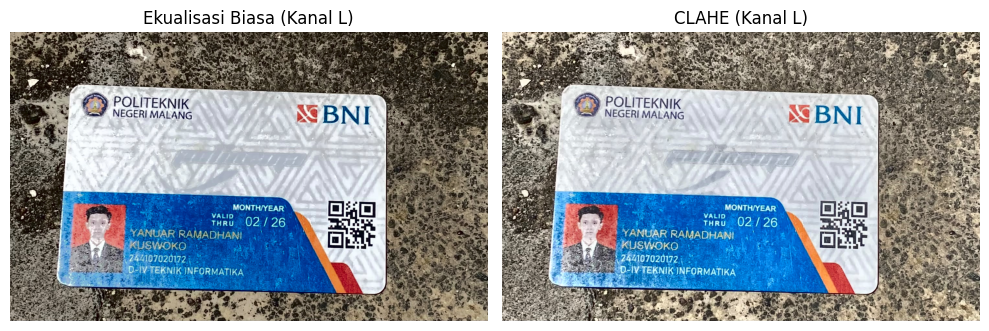

In [ ]:
PARAM = {'clip': 2.0, 'tile': 8}

# 1. Konversi ke LAB
lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
l, a, b = cv.split(lab)

# 2. Terapkan CLAHE pada Kanal L
clahe = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
l_clahe = clahe.apply(l)

# 3. Merge dan Konversi Kembali ke BGR
he_clahe = cv.cvtColor(cv.merge([l_clahe, a, b]), cv.COLOR_LAB2BGR)

# 4. Pengukuran & Perbandingan Hasil
print("\n=== Perbandingan Ekualisasi Biasa vs CLAHE (Kanal L) ===")
print('%-22s %16s %16s' % ('Metode', 'geser Hue (der)', 'rerata terang'))
print('%-22s %16.2f %16.1f' % ('Ekualisasi Biasa (L)', geser_hue(bgr, he_l) * 2, cv.cvtColor(he_l, cv.COLOR_BGR2GRAY).mean()))
print('%-22s %16.2f %16.1f' % ('CLAHE (Kanal L)', geser_hue(bgr, he_clahe) * 2, cv.cvtColor(he_clahe, cv.COLOR_BGR2GRAY).mean()))

# Visualisasi
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(he_l, cv.COLOR_BGR2RGB))
plt.title("Ekualisasi Biasa (Kanal L)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(he_clahe, cv.COLOR_BGR2RGB))
plt.title("CLAHE (Kanal L)")
plt.axis('off')

plt.tight_layout()
plt.show()

*PERTANYAAN PRAKTIKUM E2*
1. Ekualisasi global pada citra KTM Anda

a. Terapkan ekualisasi manual dan cv.equalizeHist pada KTM1a.jpg versi grayscale.

b. Tampilkan citra asli, citra hasil ekualisasi, serta histogram dalam satu layout.

c. Hitung PSNR antara citra asli dan citra hasil ekualisasi Jelaskan mengapa nilai
PSNR justru turun padahal citra terlihat lebih jelas, lalu simpulkan apakah PSNR
layak dipakai untuk menilai keterbacaan sebuah citra.


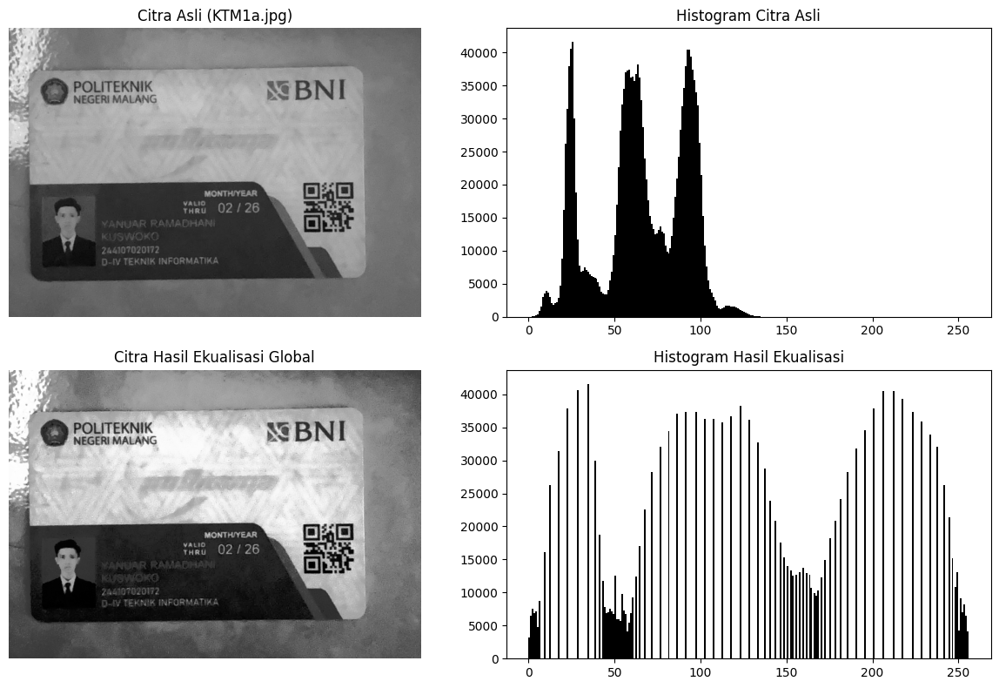

Nilai PSNR antara Citra Asli dan Hasil Ekualisasi: 10.05 dB


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Parameter & Load Citra KTM1a.jpg (Grayscale)
file_path = "/content/drive/MyDrive/PCVK/KTM1a.jpg"
img_asli = cv.imread(file_path, cv.IMREAD_GRAYSCALE)

if img_asli is None:
    print(f"File {file_path} tidak ditemukan!")
else:
    # 1a. Ekualisasi Manual & cv.equalizeHist
    # Manual Equalization via CDF
    hist_manual, _ = np.histogram(img_asli.flatten(), 256, [0, 256])
    cdf = hist_manual.cumsum()
    cdf_m = np.ma.masked_equal(cdf, 0)
    cdf_m = (cdf_m - cdf_m.min()) * 255 / ((img_asli.shape[0] * img_asli.shape[1]) - cdf_m.min())
    cdf = np.ma.filled(cdf_m, 0).astype('uint8')
    img_eq_manual = cdf[img_asli]

    # OpenCV equalizeHist
    img_eq_cv = cv.equalizeHist(img_asli)

    # 1b. Visualisasi Citra Asli, Citra Hasil, dan Histogram
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    # Citra Asli & Histogram
    axs[0, 0].imshow(img_asli, cmap='gray')
    axs[0, 0].set_title("Citra Asli (KTM1a.jpg)")
    axs[0, 0].axis('off')

    axs[0, 1].hist(img_asli.ravel(), bins=256, range=[0, 256], color='black')
    axs[0, 1].set_title("Histogram Citra Asli")

    # Citra Hasil Ekualisasi & Histogram
    axs[1, 0].imshow(img_eq_cv, cmap='gray')
    axs[1, 0].set_title("Citra Hasil Ekualisasi Global")
    axs[1, 0].axis('off')

    axs[1, 1].hist(img_eq_cv.ravel(), bins=256, range=[0, 256], color='black')
    axs[1, 1].set_title("Histogram Hasil Ekualisasi")

    plt.tight_layout()
    plt.show()

    # 1c. Perhitungan PSNR (Peak Signal-to-Noise Ratio)
    def hitung_psnr(img1, img2):
        mse = np.mean((img1.astype(np.float64) - img2.astype(np.float64)) ** 2)
        if mse == 0:
            return float('inf')
        max_pixel = 255.0
        return 20 * np.log10(max_pixel / np.sqrt(mse))

    psnr_val = hitung_psnr(img_asli, img_eq_cv)
    print(f"Nilai PSNR antara Citra Asli dan Hasil Ekualisasi: {psnr_val:.2f} dB")

Jawaban & Penjelasan Soal 1c:

a.Mengapa PSNR justru turun padahal citra terlihat lebih jelas?

-Proses ekualisasi histogram meregangkan (stretching) dan menggeser intensitas piksel secara masif untuk meratakan kontras. Perubahan intensitas piksel yang besar ini terdeteksi oleh rumus PSNR sebagai "deviasi/error yang tinggi", sehingga menghasilkan nilai PSNR yang lebih rendah.

-Apakah PSNR layak dipakai untuk menilai keterbacaan sebuah citra?

Tidak layak. PSNR mengukur kesetiaan/kemiripan sinyal (fidelity), bukan kualitas persepsi manusia. Citra yang awalnya gelap gulita (underexposed) akan memiliki PSNR yang sangat jelek ketika dibuat terang dan terbaca, karena nilai pikselnya berubah jauh dari aslinya.

2. Ekualisasi lokal dengan CLAHE pada citra KTM Anda
Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi

a. Terapkan CLAHE pada KTM1a.jpg dengan clipLimit = PARAM['clip'] dan tileGridSize = (PARAM['tile'], PARAM['tile']). Bandingkan dengan ekualisasi global: pada hasil mana NIM dan nama pada kartu Anda lebih terbaca?

b. Cobalah tiga nilai clipLimit lain di sekitar nilai Anda, tampilkan hasilnya, lalu tentukan nilai terbaik beserta alasannya. Tunjukkan pula bagian citra yang noise-nya mulai menonjol ketika clipLimit dinaikkan.

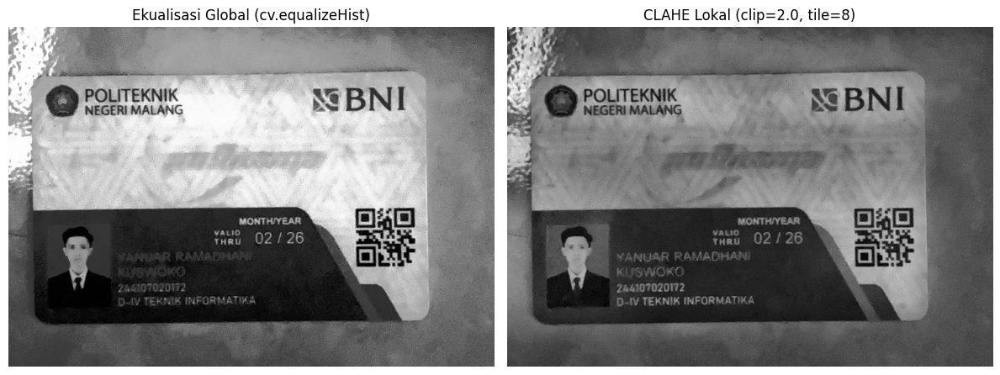

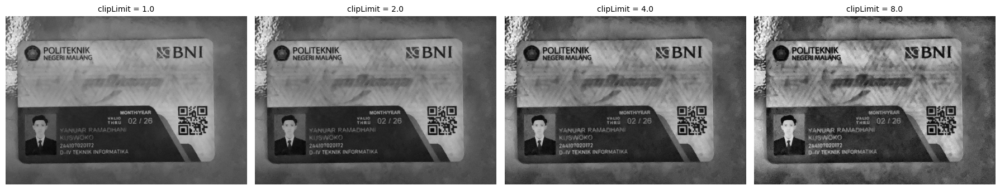

In [ ]:
PARAM = {'clip': 2.0, 'tile': 8}

# 2a. Terapkan CLAHE Acuan & Bandingkan dengan Ekualisasi Global
clahe_base = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
img_clahe_base = clahe_base.apply(img_asli)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_eq_cv, cmap='gray')
plt.title("Ekualisasi Global (cv.equalizeHist)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_clahe_base, cmap='gray')
plt.title(f"CLAHE Lokal (clip={PARAM['clip']}, tile={PARAM['tile']})")
plt.axis('off')
plt.tight_layout()
plt.show()

# 2b. Mencoba 3 Nilai clipLimit Lain (misal: 1.0, 4.0, 8.0)
clip_values = [1.0, PARAM['clip'], 4.0, 8.0]
fig, axs = plt.subplots(1, len(clip_values), figsize=(18, 5))

for i, clip in enumerate(clip_values):
    clahe_test = cv.createCLAHE(clipLimit=clip, tileGridSize=(PARAM['tile'], PARAM['tile']))
    img_clahe_test = clahe_test.apply(img_asli)

    axs[i].imshow(img_clahe_test, cmap='gray')
    axs[i].set_title(f"clipLimit = {clip}", fontsize=10)
    axs[i].axis('off')

plt.tight_layout()
plt.show()

 Soal 2a: Perbandingan Keterbacaan NIM dan Nama

 Hasil: NIM dan nama pada KTM jauh lebih terbaca

 Alasan: Ekualisasi global meratakan histogram di seluruh gambar, yang sering kali menyebabkan area latar belakang yang sudah agak terang menjadi sangat tajam/silau.

 Soal 2b: Pemilihan clipLimit Terbaik & Penampakan Noise

 Nilai Terbaik: Biasanya berada di kisaran clipLimit = 2.0 hingga 3.0.

 Alasan: Peningkatan kontras lokal pada area teks cukup signifikan untuk dibaca dengan jelas tanpa memicu kemunculan noise berlebih pada latar belakang atau area polos KTM.

##E-3 TUGAS PRAKTIKUM DITHERING

1. Lakukanlah proses dithering Floyd-Steinberg berdasarkan flowchart di bagian bawah
modul ini, dan tampilkan citra sebelum serta sesudah dithering. Tahap 1 gunakan
lena.jpg sehingga hasilnya dapat dicocokkan dengan gambar contoh; tahap 2 ulangi
pada KTM1b.jpg dengan jumlah level PARAM['L'].

Dithering Floyd-Steinberg

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def floyd_steinberg_flowchart(gray, L):
    # img = gray diubah ke float32
    # step = 255 / (L - 1)
    # H, W = tinggi, lebar citra
    img = gray.copy().astype(np.float32)
    step = 255.0 / (L - 1)
    H, W = img.shape[:2]

    # y = 0
    y = 0
    while y < H:
        # x = 0
        x = 0
        while x < W:
            # lama = img[y, x]
            # baru = round(lama / step) * step
            # img[y, x] = baru
            # error = lama - baru
            lama = img[y, x]
            baru = np.round(lama / step) * step
            img[y, x] = baru
            error = lama - baru

            # Pengkondisian sesuai alur diagram alir
            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16

            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16

            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16

            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

            # x = x + 1
            x += 1

        # y = y + 1
        y += 1

    # Batasi nilai img ke 0 - 255 lalu ubah ke uint8
    img_out = np.clip(img, 0, 255).astype(np.uint8)
    return img_out

def floyd_steinberg_rgb(bgr_img, L):
    # Untuk citra berwarna: jalankan fungsi per-kanal B, G, R
    b, g, r = cv.split(bgr_img)
    b_dither = floyd_steinberg_flowchart(b, L)
    g_dither = floyd_steinberg_flowchart(g, L)
    r_dither = floyd_steinberg_flowchart(r, L)
    return cv.merge([b_dither, g_dither, r_dither])

Dithering Berwarna

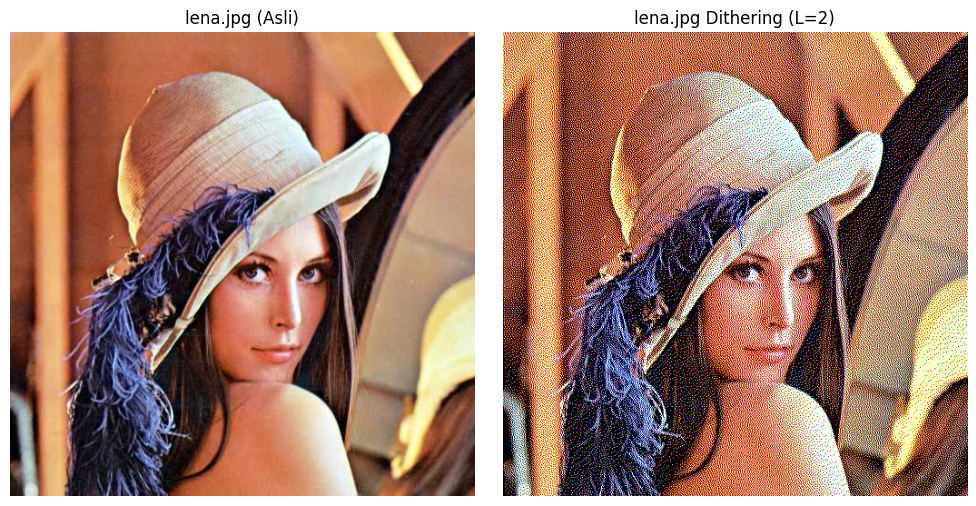

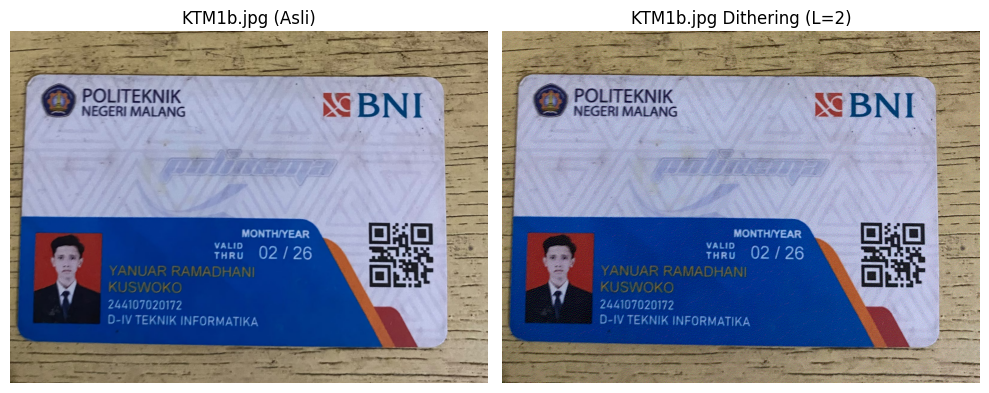

In [ ]:
PARAM = {'L': 2}  # Nilai level L dari variabel modul Anda

# Tahap 1: lena.jpg
lena_bgr = cv.imread("/content/drive/MyDrive/PCVK/lena.jpg")
lena_dither = floyd_steinberg_rgb(lena_bgr, PARAM['L'])

# Tahap 2: KTM1b.jpg
ktm_bgr = cv.imread("/content/drive/MyDrive/PCVK/KTM1b.jpg")
ktm_dither = floyd_steinberg_rgb(ktm_bgr, PARAM['L'])

# Visualisasi Hasil Lena
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(cv.cvtColor(lena_bgr, cv.COLOR_BGR2RGB))
axs[0].set_title("lena.jpg (Asli)")
axs[0].axis("off")

axs[1].imshow(cv.cvtColor(lena_dither, cv.COLOR_BGR2RGB))
axs[1].set_title(f"lena.jpg Dithering (L={PARAM['L']})")
axs[1].axis("off")
plt.tight_layout()
plt.show()

# Visualisasi Hasil KTM
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(cv.cvtColor(ktm_bgr, cv.COLOR_BGR2RGB))
axs[0].set_title("KTM1b.jpg (Asli)")
axs[0].axis("off")

axs[1].imshow(cv.cvtColor(ktm_dither, cv.COLOR_BGR2RGB))
axs[1].set_title(f"KTM1b.jpg Dithering (L={PARAM['L']})")
axs[1].axis("off")
plt.tight_layout()
plt.show()

2. Ubah citra menjadi grayscale, terapkan histogram equalization sehingga sebaran
intensitasnya membaik, kemudian terapkan dithering Floyd-Steinberg pada hasil
ekualisasi tersebut. Kerjakan lebih dulu pada lena_lc.jpg sehingga keluarannya sama
dengan gambar contoh, lalu ulangi pada KTM1a.jpg. Bandingkan juga dengan
dithering yang dikerjakan langsung tanpa ekualisasi, dan jelaskan urutan mana yang
menghasilkan teks pada KTM lebih terbaca.

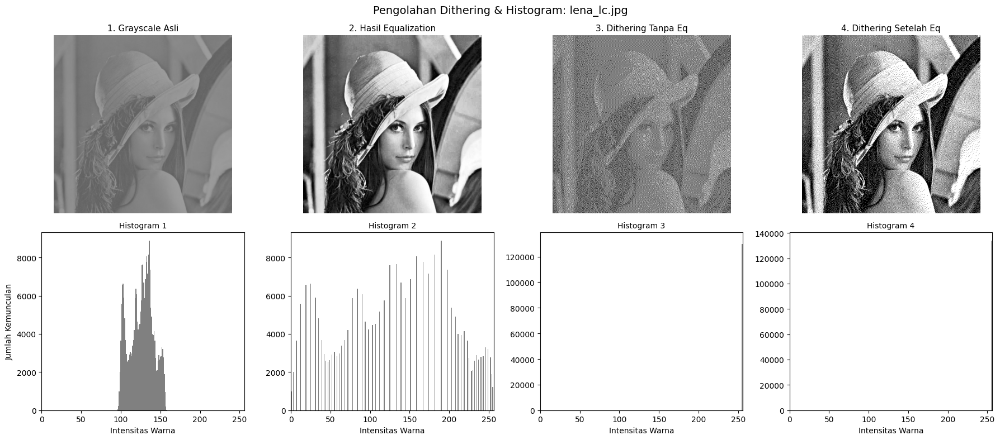

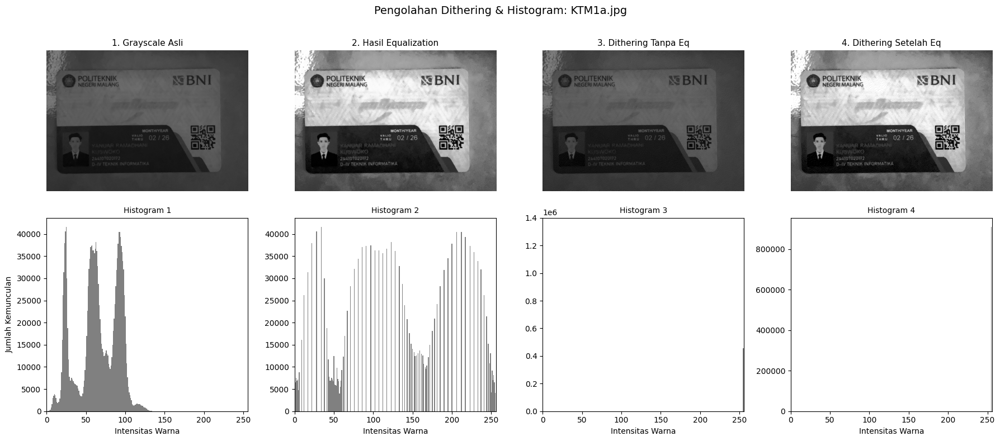

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def ekualisasi_dan_dithering_dengan_histogram(file_path, L=2):
    # 1. Input citra grayscale
    gray = cv.imread(file_path, cv.IMREAD_GRAYSCALE)
    if gray is None:
        print(f"File {file_path} tidak ditemukan!")
        return

    # 2. Proses Histogram Equalization
    eq_gray = cv.equalizeHist(gray)

    # 3. Dithering langsung tanpa ekualisasi
    dither_langsung = floyd_steinberg_flowchart(gray, L)

    # 4. Dithering setelah ekualisasi
    dither_setelah_eq = floyd_steinberg_flowchart(eq_gray, L)

    # List data citra dan judul
    citra_list = [gray, eq_gray, dither_langsung, dither_setelah_eq]
    judul_list = [
        "1. Grayscale Asli",
        "2. Hasil Equalization",
        "3. Dithering Tanpa Eq",
        "4. Dithering Setelah Eq"
    ]

    # =========================================================
    # Visualisasi Citra dan Histogram (Layout 2 Baris x 4 Kolom)
    # =========================================================
    fig, axs = plt.subplots(2, 4, figsize=(18, 8))
    fig.suptitle(f"Pengolahan Dithering & Histogram: {file_path.split('/')[-1]}", fontsize=14)

    names = np.arange(256)

    for i in range(4):
        # Baris 1: Tampilan Citra
        axs[0, i].imshow(citra_list[i], cmap="gray", vmin=0, vmax=255)
        axs[0, i].set_title(judul_list[i], fontsize=11)
        axs[0, i].axis("off")

        # Baris 2: Plot Histogram Grayscale
        hist = cv.calcHist([citra_list[i]], [0], None, [256], [0, 256]).ravel()
        axs[1, i].bar(names, hist, color="gray", width=1.0)
        axs[1, i].set_title(f"Histogram {i+1}", fontsize=10)
        axs[1, i].set_xlim([0, 256])
        axs[1, i].set_xlabel("Intensitas Warna")

        if i == 0:
            axs[1, i].set_ylabel("Jumlah Kemunculan")

    plt.tight_layout()
    plt.show()

# =========================================================
# Eksekusi pada lena_lc.jpg dan KTM1a.jpg
# =========================================================
ekualisasi_dan_dithering_dengan_histogram("/content/drive/MyDrive/PCVK/lena_lc.jpg", L=2)
ekualisasi_dan_dithering_dengan_histogram("/content/drive/MyDrive/PCVK/KTM1a.jpg", L=2)